In [2]:
import pandas as pd
path = r"C:\Users\rober\OneDrive\Desktop\bank_showdown\complaints.csv"

In [3]:
import os
print(os.listdir(path))

['complaints.csv']


In [4]:
import pandas as pd

path = r"C:\Users\rober\OneDrive\Desktop\bank_showdown\complaints.csv\complaints.csv"

banks = ["CITIZENS FINANCIAL", "JPMORGAN", "BANK OF AMERICA", "WELLS FARGO",
         "CAPITAL ONE", "DISCOVER", "ALLY FINANCIAL", "PAYPAL", "BLOCK, INC", "CHIME"]
pattern = "|".join(banks)

cols = ["Date received", "Product", "Issue", "Company",
        "Company response to consumer", "Timely response?"]

pieces = []
for chunk in pd.read_csv(path, usecols=cols, parse_dates=["Date received"], chunksize=200_000):
    chunk = chunk[chunk["Date received"] >= "2021-01-01"]
    chunk = chunk[chunk["Company"].str.upper().str.contains(pattern, na=False)]
    pieces.append(chunk)

df = pd.concat(pieces)
df.to_csv("complaints_filtered.csv", index=False)

print(df.shape)
print(df["Company"].value_counts().head(20))

(615904, 6)
Company
CAPITAL ONE FINANCIAL CORPORATION        126371
JPMORGAN CHASE & CO.                     103861
WELLS FARGO & COMPANY                     93933
BANK OF AMERICA, NATIONAL ASSOCIATION     92405
Block, Inc.                               70932
Paypal Holdings, Inc                      34850
DISCOVER BANK                             30087
Chime Financial Inc                       29241
ALLY FINANCIAL INC.                       23055
CITIZENS FINANCIAL GROUP, INC.            10900
Chime Inc.                                  253
Discovery Auto Sales LLC                     16
Name: count, dtype: int64


In [5]:
df = df[df["Company"] != "Discovery Auto Sales LLC"].copy()

names = {
    "CAPITAL ONE FINANCIAL CORPORATION": "Capital One",
    "JPMORGAN CHASE & CO.": "Chase",
    "WELLS FARGO & COMPANY": "Wells Fargo",
    "BANK OF AMERICA, NATIONAL ASSOCIATION": "Bank of America",
    "Block, Inc.": "Block (Cash App)",
    "Paypal Holdings, Inc": "PayPal",
    "DISCOVER BANK": "Discover",
    "Chime Financial Inc": "Chime",
    "Chime Inc.": "Chime",
    "ALLY FINANCIAL INC.": "Ally",
    "CITIZENS FINANCIAL GROUP, INC.": "Citizens",
}
df["Bank"] = df["Company"].map(names)

groups = {
    "Chase": "Big Bank", "Bank of America": "Big Bank", "Wells Fargo": "Big Bank",
    "Capital One": "Big Bank", "Citizens": "Big Bank",
    "Ally": "Online Bank", "Discover": "Online Bank",
    "Block (Cash App)": "Fintech", "PayPal": "Fintech", "Chime": "Fintech",
}
df["Group"] = df["Bank"].map(groups)
df["Year"] = df["Date received"].dt.year

print("Unmatched banks:", df["Bank"].isna().sum())
print(df["Bank"].value_counts())
print(df["Date received"].min(), df["Date received"].max())
print(df["Company response to consumer"].value_counts())
print(df["Timely response?"].value_counts())

df.to_csv("complaints_clean.csv", index=False)

Unmatched banks: 0
Bank
Capital One         126371
Chase               103861
Wells Fargo          93933
Bank of America      92405
Block (Cash App)     70932
PayPal               34850
Discover             30087
Chime                29494
Ally                 23055
Citizens             10900
Name: count, dtype: int64
2021-01-01 00:00:00 2026-10-27 00:00:00
Company response to consumer
Closed with explanation            494812
Closed with non-monetary relief     60026
Closed with monetary relief         55549
In progress                          5490
Untimely response                      10
Name: count, dtype: int64
Timely response?
Yes    612021
No       3867
Name: count, dtype: int64


                  Complaints  Relief %  Monetary relief %  Timely %
Bank                                                               
PayPal                 34850     32.70              14.16     99.94
Bank of America        92405     31.94              24.59     96.97
Discover               30087     28.50               4.23    100.00
Wells Fargo            93933     20.30               8.17     99.99
Capital One           126371     18.52               5.37     99.99
Chase                 103861     17.31               8.14    100.00
Citizens               10900     15.88              15.88     99.98
Ally                   23055     10.43               3.39    100.00
Chime                  29494      8.45               5.92     99.77
Block (Cash App)       70932      0.17               0.17     98.65
Bank  Ally  Bank of America  Block (Cash App)  Capital One  Chase  Chime  \
Year                                                                       
2021  2232            11427     

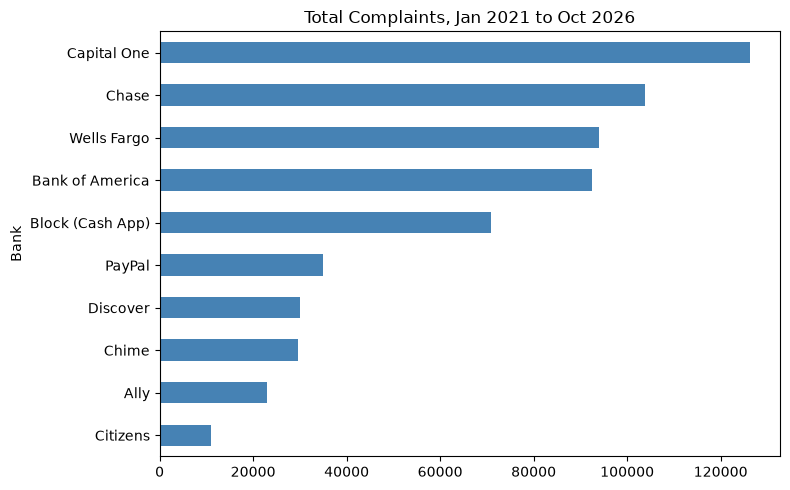

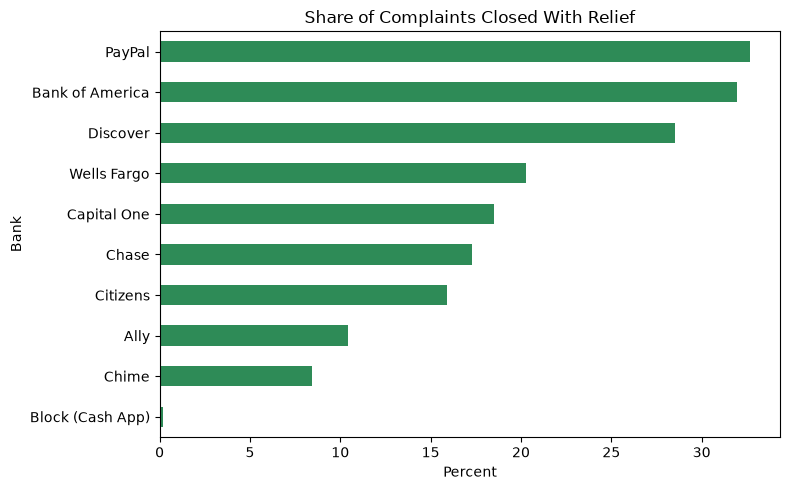

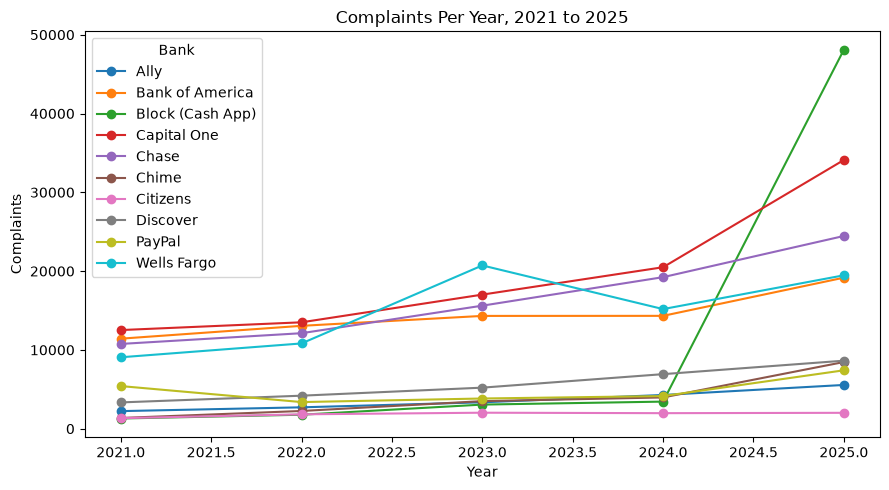

In [6]:
import matplotlib.pyplot as plt

closed = df[df["Company response to consumer"] != "In progress"]

summary = pd.DataFrame({
    "Complaints": df.groupby("Bank").size(),
    "Relief %": closed.groupby("Bank")["Company response to consumer"]
        .apply(lambda s: s.str.contains("relief").mean() * 100),
    "Monetary relief %": closed.groupby("Bank")["Company response to consumer"]
        .apply(lambda s: (s == "Closed with monetary relief").mean() * 100),
    "Timely %": df.groupby("Bank")["Timely response?"]
        .apply(lambda s: (s == "Yes").mean() * 100),
}).round(2).sort_values("Relief %", ascending=False)

print(summary)

yearly = df.groupby(["Year", "Bank"]).size().unstack().loc[2021:2025]
print(yearly)

summary.to_csv("summary_table.csv")

plt.figure(figsize=(8, 5))
summary["Complaints"].sort_values().plot(kind="barh", color="steelblue")
plt.title("Total Complaints, Jan 2021 to Oct 2026")
plt.tight_layout()
plt.savefig("chart_total_complaints.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
summary["Relief %"].sort_values().plot(kind="barh", color="seagreen")
plt.title("Share of Complaints Closed With Relief")
plt.xlabel("Percent")
plt.tight_layout()
plt.savefig("chart_relief_rate.png", dpi=200)
plt.show()

yearly.plot(figsize=(9, 5), marker="o")
plt.title("Complaints Per Year, 2021 to 2025")
plt.ylabel("Complaints")
plt.tight_layout()
plt.savefig("chart_yearly_trend.png", dpi=200)
plt.show()